In [1]:
import os
import pandas as pd
import librosa
import torch
import numpy as np
import torchaudio

import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable

from IPython.display import Audio, display


In [2]:
class STFTWindowParams:
    def __init__(self, sample_rate=16000, win_sec=0.032, hop_sec=0.016):
        self.sample_rate = sample_rate
        self.win_sec = win_sec
        self.hop_sec = hop_sec

        self.update()

    def update(self):
        self.win_size = int(self.win_sec * self.sample_rate)
        self.hop_size = int(self.hop_sec * self.sample_rate)
        self.fft_size = self.next_pow_2(self.win_size)

    @staticmethod
    def next_pow_2(x):
        return 2 ** (x - 1).bit_length()


# USING THE MIDDLE WINDOW
def prepare_audio_window(x, max_len, is_eval=False):
    x_len = x.shape[0]

    while x_len < max_len:
        num_samples = min(x_len, max_len - x_len)
        x = torch.cat([x, x[:num_samples]], dim=0)
        x_len = x.shape[0]

    num_windows = round(x_len / max_len)
    if num_windows % 2 == 1:  # odd no. of windows
        middle = num_windows//2
    else:  # even no. of windows
        middle = (num_windows//2) - 1

    start_sample = middle * max_len
    x_pad = x[start_sample: start_sample + max_len]

    return x_pad


# Extract linear mag
def extract_mag(x):
    
    stft_params = STFTWindowParams()
    window = torch.hann_window(stft_params.fft_size, device='cpu')
    
    X = torch.stft(
        x,
        n_fft=stft_params.fft_size,
        hop_length=stft_params.hop_size,
        win_length=stft_params.win_size,
        window=window,
        center=True,
        return_complex=True
    )
    
    mag = torch.abs(X)
    phase = torch.angle(X)
    
    return mag, phase



def mag_to_db(mag):
    return torchaudio.functional.amplitude_to_DB(
        mag,
        multiplier=20.0,  
        amin=1e-10,
        db_multiplier=1.0
    )

def load_real_audio(name):
    path = os.path.join(real_dir, f"{name}.flac")
    x, _ = librosa.load(path, sr=None)
    x = torch.Tensor(x)
    return x.squeeze()


def db_to_mag(db):
    return torch.pow(10.0, db / 20.0)

def mag_phase_to_audio(mag, phase):

    stft_params = STFTWindowParams()
    window = torch.hann_window(stft_params.fft_size, device='cpu')
    
    X = mag * torch.exp(1j * phase)

    x = torch.istft(
        X,
        n_fft=stft_params.fft_size,
        hop_length=stft_params.hop_size,
        win_length=stft_params.win_size,
        window=window,
        center=True,
        length=None
    )
    return x

In [3]:
real_dir = '/Database/ASVspoof5/flac_D'
examples_dir = '/home/smg/v-viola/moe_antideepfake/examples/pitch'

In [9]:
mod_dir = os.path.join(examples_dir, 'f0_shift_all')
mod_files = sorted([f for f in os.listdir(mod_dir) if f.endswith('.npy')])


In [10]:
rows = []

for f in mod_files:
    name = os.path.splitext(f)[0]

    max_len = int(3.0 * 16000)  

    x_real = load_real_audio(name)
    x_real = prepare_audio_window(x_real, max_len)
    mag_real, _ = extract_mag(x_real)

    mag_mod = torch.from_numpy(np.load(os.path.join(mod_dir, f))).float()

    rows.append({
        "name": name,
        "mag_real": mag_to_db(mag_real),
        "mag_mod": mag_to_db(mag_mod)
    })

df = pd.DataFrame(rows)
df

,name,mag_real,mag_mod
0,D_0000055420,"[[tensor(-37.3690), tensor(-27.1674), tensor(-...","[[tensor(-37.3690), tensor(-27.1674), tensor(-..."
1,D_0000060292,"[[tensor(1.4137), tensor(2.4264), tensor(-26.1...","[[tensor(1.4137), tensor(2.4264), tensor(-26.1..."
2,D_0000068419,"[[tensor(1.9004), tensor(2.3165), tensor(9.554...","[[tensor(1.9004), tensor(2.3165), tensor(9.554..."
3,D_0000133393,"[[tensor(-10.3585), tensor(-15.2811), tensor(-...","[[tensor(-10.3585), tensor(-15.2811), tensor(-..."
4,D_0000141415,"[[tensor(-28.7164), tensor(-65.1754), tensor(-...","[[tensor(-28.7164), tensor(-65.1754), tensor(-..."
...,...,...,...
83,D_0002771287,"[[tensor(-48.3308), tensor(-28.8873), tensor(-...","[[tensor(-48.3308), tensor(-28.8873), tensor(-..."
84,D_0002799868,"[[tensor(-69.8282), tensor(-67.0967), tensor(-...","[[tensor(-69.8282), tensor(-67.0967), tensor(-..."
85,D_0002814316,"[[tensor(-79.7712), tensor(-83.6645), tensor(-...","[[tensor(-79.7712), tensor(-83.6645), tensor(-..."
86,D_0002909005,"[[tensor(-18.7357), tensor(-30.0039), tensor(-...","[[tensor(-18.7755), tensor(-30.0436), tensor(-..."


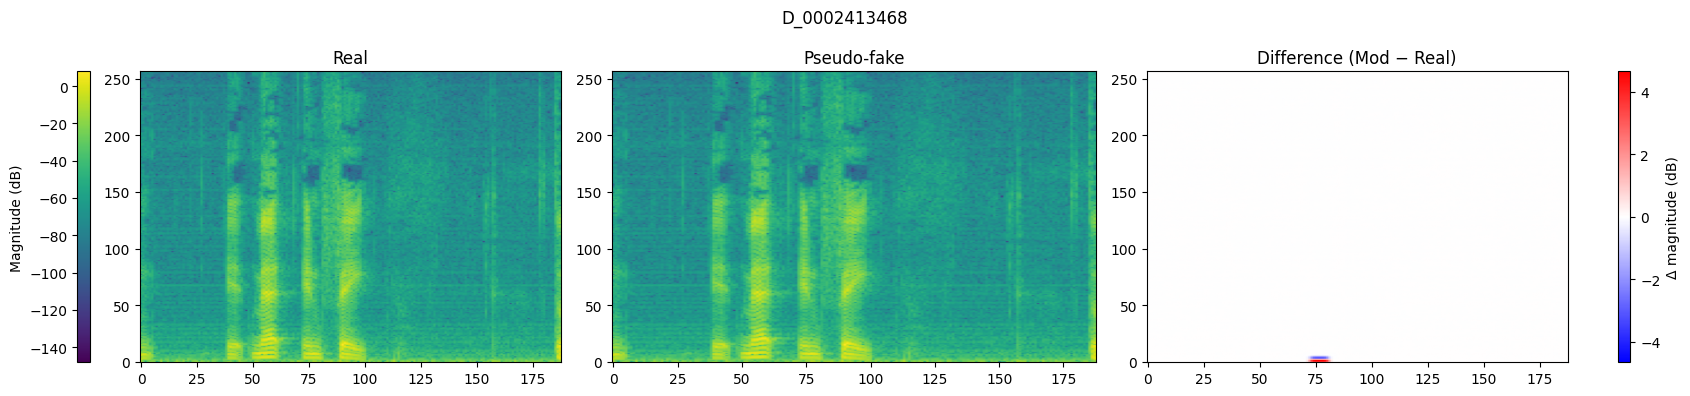

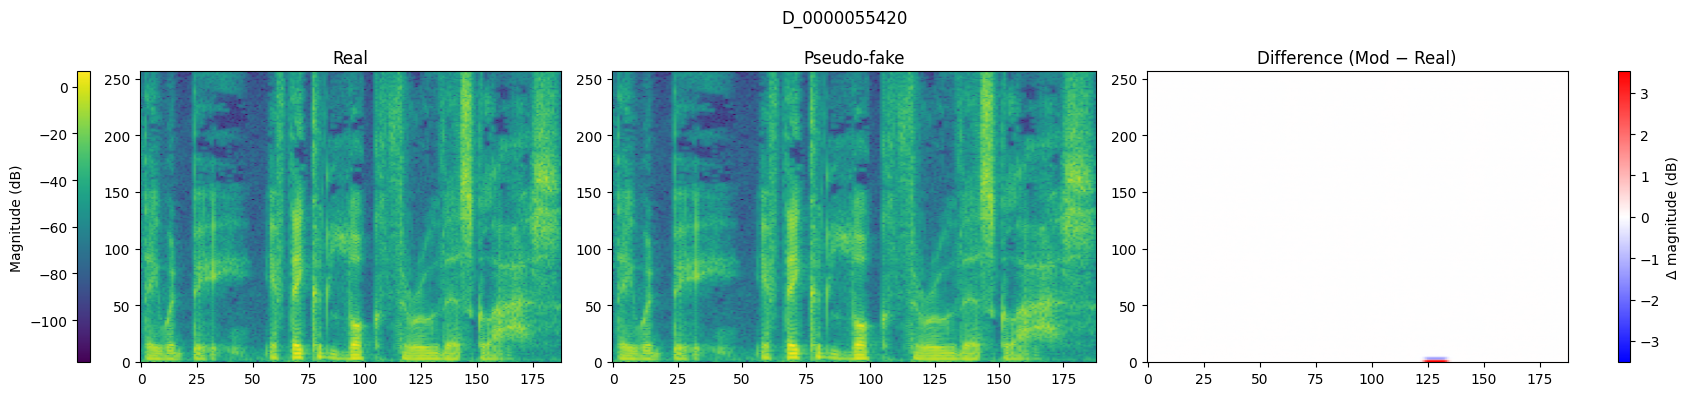

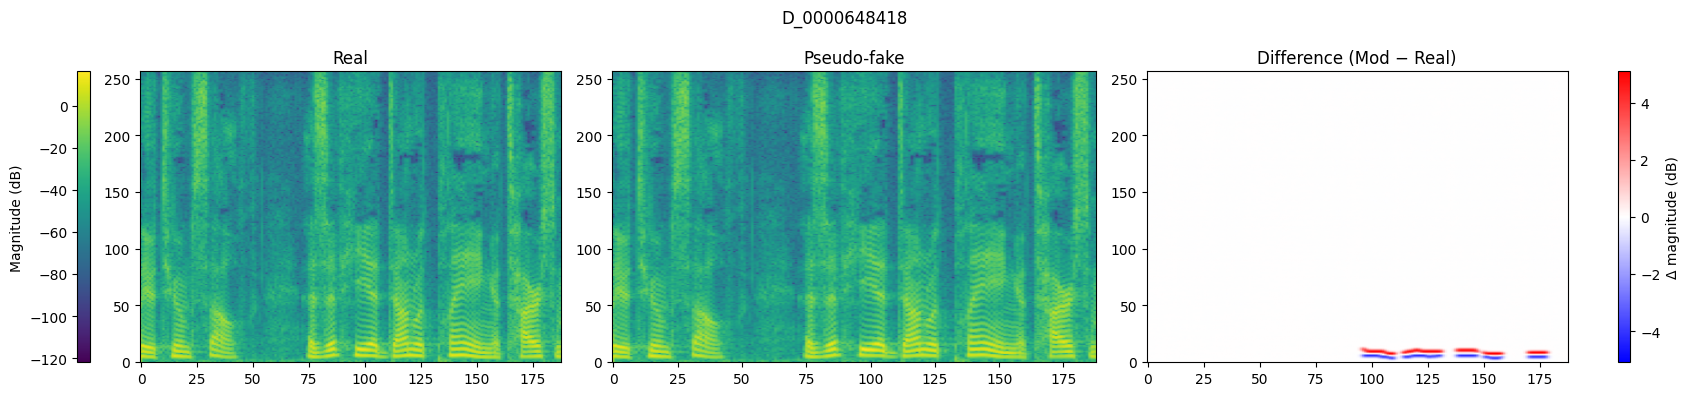

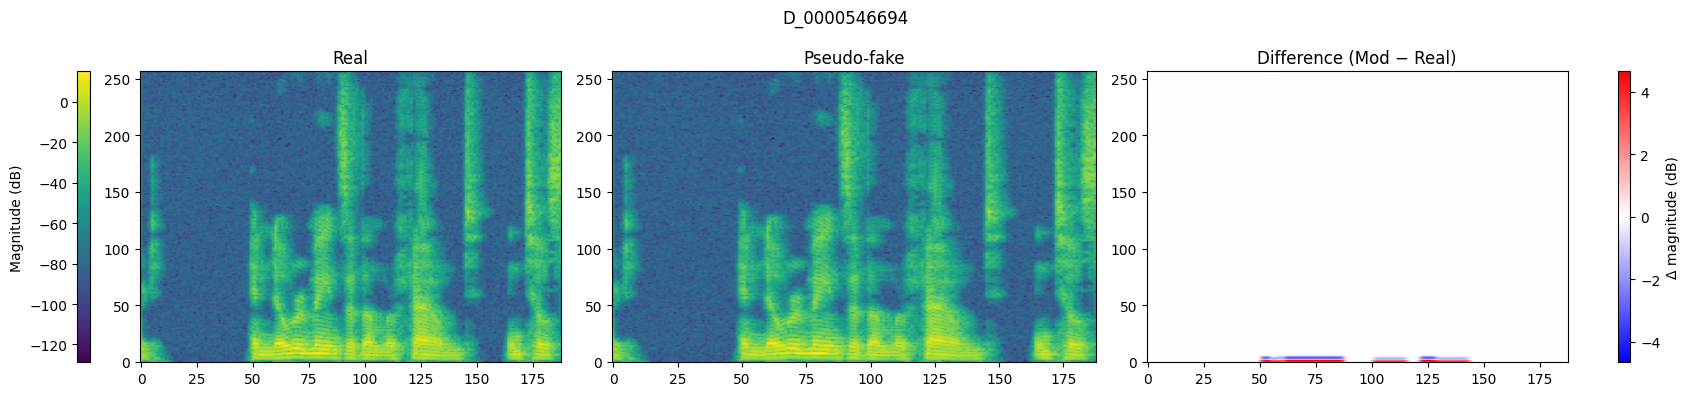

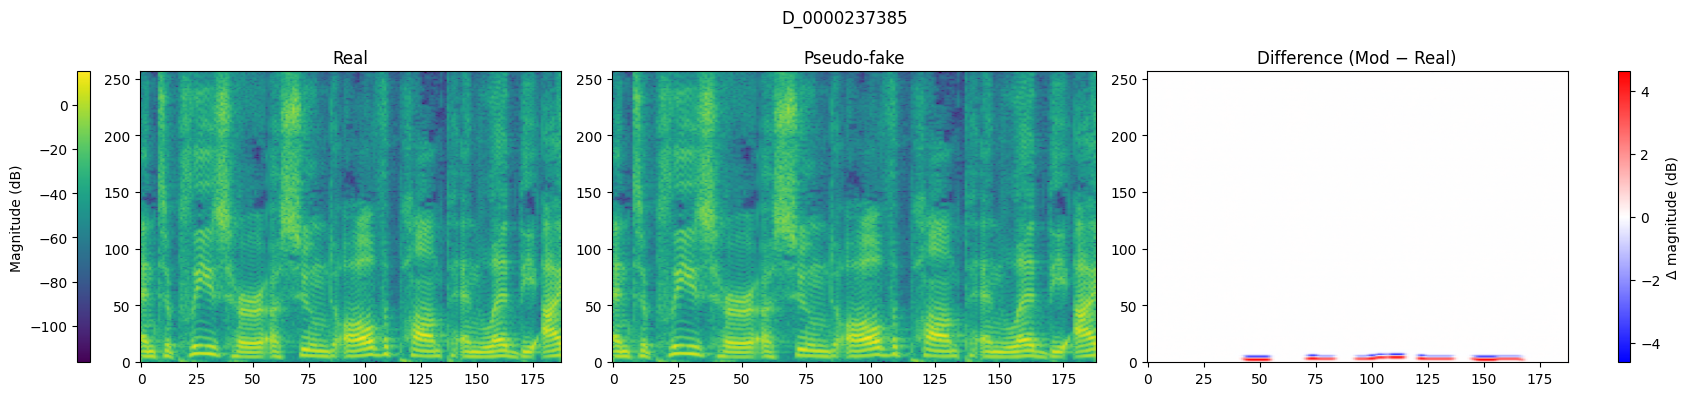

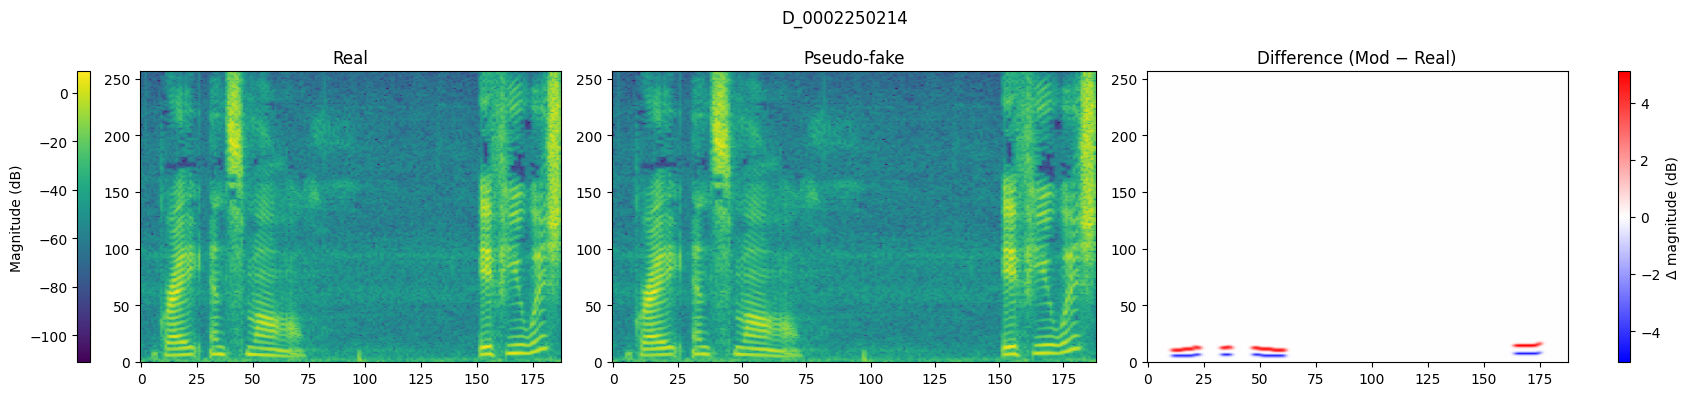

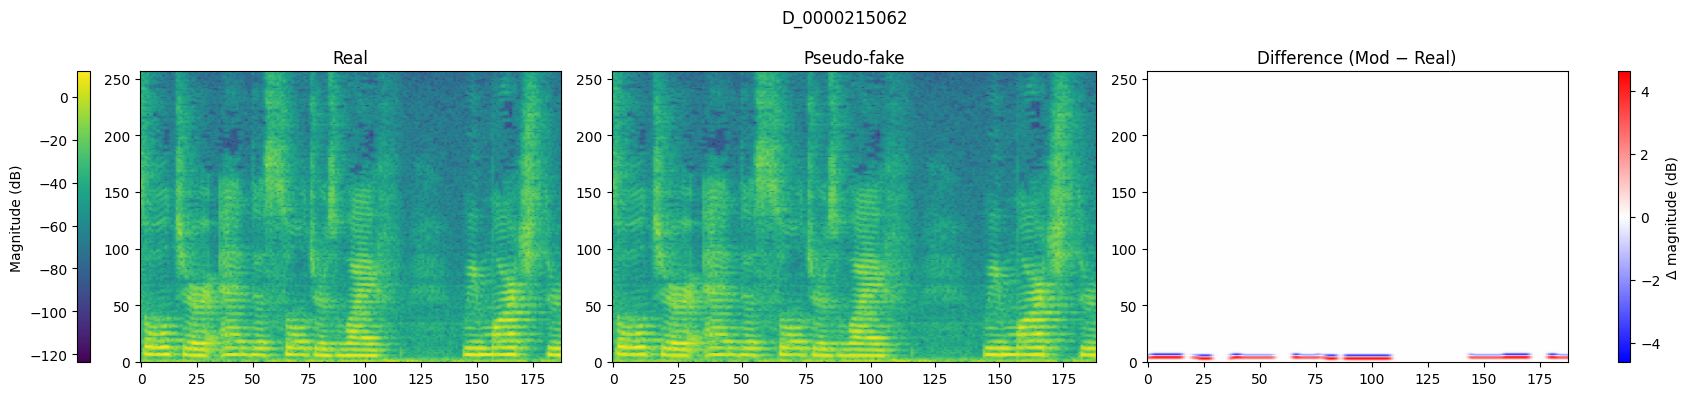

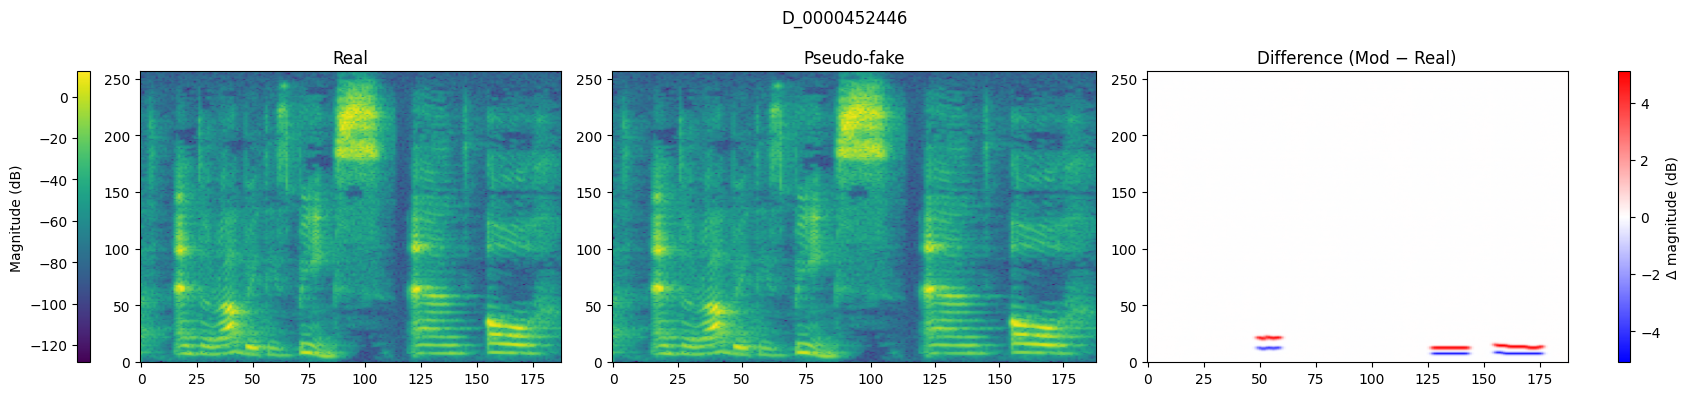

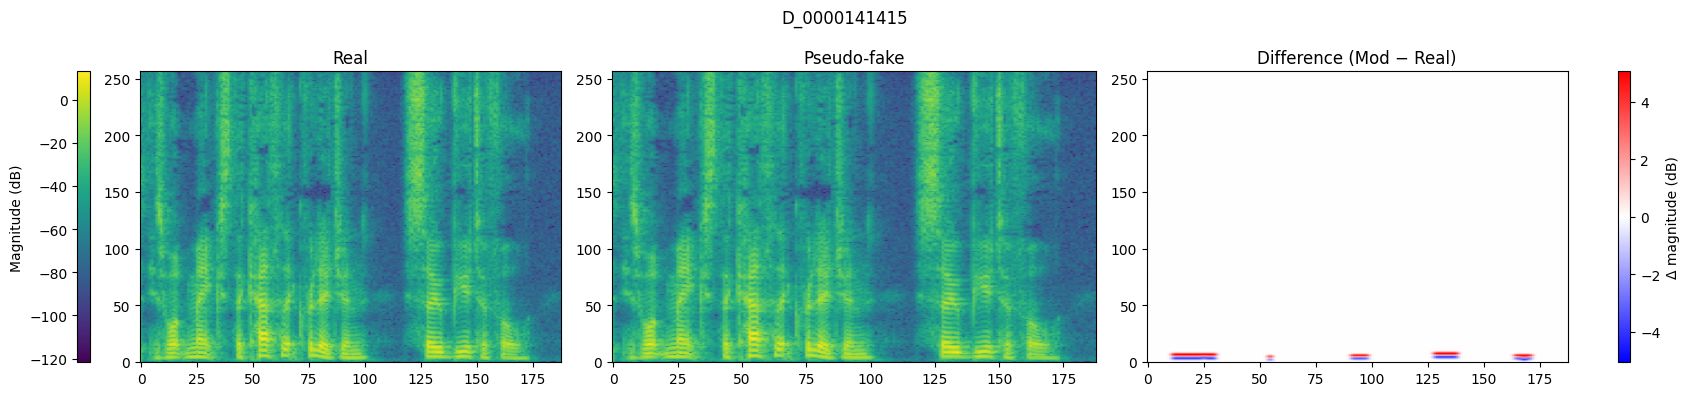

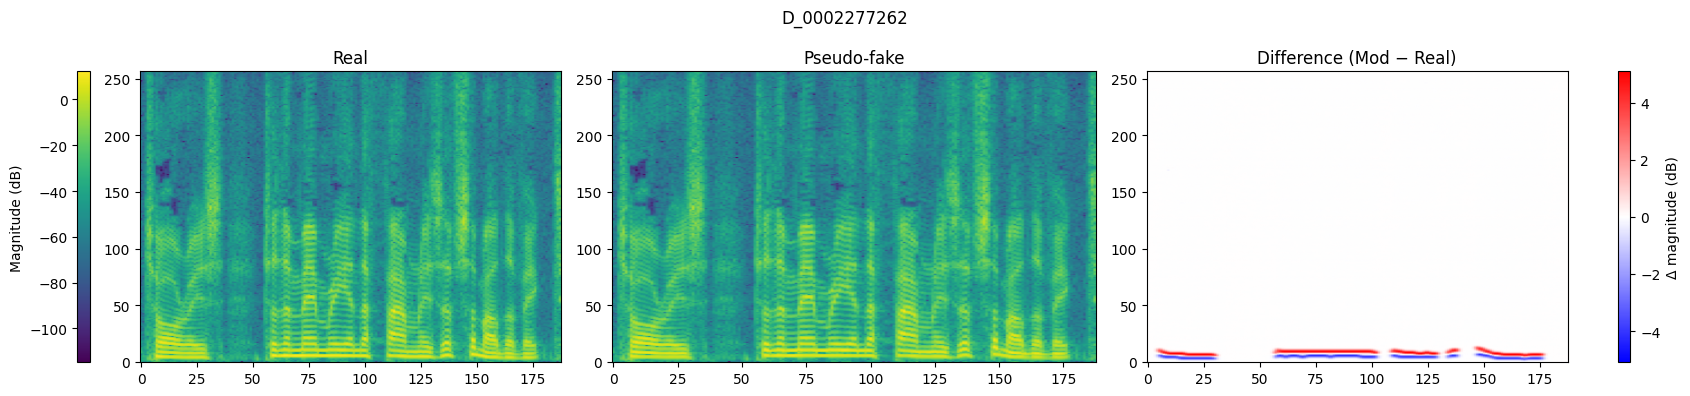

In [11]:
for _, row in df.sample(10, random_state=42).iterrows():
    fig, ax = plt.subplots(1, 3, figsize=(17, 4))

    # shared scale for real & mod
    vmin = min(row["mag_real"].min(), row["mag_mod"].min())
    vmax = max(row["mag_real"].max(), row["mag_mod"].max())

    im0 = ax[0].imshow(row["mag_real"], origin='lower', aspect='auto',
                       vmin=vmin, vmax=vmax)
    ax[0].set_title("Real")

    ax[1].imshow(row["mag_mod"], origin='lower', aspect='auto',
                 vmin=vmin, vmax=vmax)
    ax[1].set_title("Pseudo-fake")

    # difference
    diff = row["mag_mod"] - row["mag_real"]
    dmax = diff.abs().max()

    im2 = ax[2].imshow(diff, origin='lower', aspect='auto',
                       cmap='bwr', vmin=-dmax, vmax=dmax)
    ax[2].set_title("Difference (Mod − Real)")

    # ── colorbar for Real + Pseudo-fake (LEFT)
    divider0 = make_axes_locatable(ax[0])
    cax0 = divider0.append_axes("left", size="3%", pad=0.5)
    cbar0 = fig.colorbar(im0, cax=cax0)
    cbar0.set_label("Magnitude (dB)")
    cax0.yaxis.set_ticks_position('left')
    cax0.yaxis.set_label_position('left')

    # ── colorbar for Difference (RIGHT)
    divider2 = make_axes_locatable(ax[2])
    cax2 = divider2.append_axes("right", size="3%", pad=0.5)
    cbar2 = fig.colorbar(im2, cax=cax2)
    cbar2.set_label("Δ magnitude (dB)")

    plt.suptitle(row["name"])
    plt.tight_layout()
    plt.show()


In [12]:
name = "D_0002277262"
row = df.loc[df["name"] == name].iloc[0]

x_real = load_real_audio(row["name"])
x_real = prepare_audio_window(x_real, int(3.0 * 16000))

mag_real, phase_real = extract_mag(x_real)
mag_mod = row["mag_mod"]
mag_real = row["mag_real"]

mag_real_lin = db_to_mag(mag_real)
mag_mod_lin = db_to_mag(mag_mod)

x_real_rec = mag_phase_to_audio(mag_real_lin, phase_real)
x_mod_rec  = mag_phase_to_audio(mag_mod_lin, phase_real)


print("Real (original)")
display(Audio(x_real.numpy(), rate=16000))

print("Real (reconstructed)")
display(Audio(x_real_rec.numpy(), rate=16000))

print("Pseudo-fake + original phase")
display(Audio(x_mod_rec.numpy(), rate=16000))


Real (original)


Real (reconstructed)


Pseudo-fake + original phase
